In [1]:
from pathlib import Path
import os
import sys

# 无论从仓库根目录还是 notebook 目录启动，都统一回到仓库根目录。
repo_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / 'factors').is_dir() and (path / 'data').is_dir()
)
os.chdir(repo_root)
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

%load_ext autoreload
%autoreload 2

In [ ]:
# 临时测试，请勿参考
from pathlib import Path
(Path.cwd(), *Path.cwd().parents)

(WindowsPath('d:/量化策略/CTA策略/early-bird-alpha'),
 WindowsPath('d:/量化策略/CTA策略'),
 WindowsPath('d:/量化策略'),
 WindowsPath('d:/'))

# 展期收益率单因子实验 `RollYieldFactor`

本实验固定使用 2000-01-01 至 2024-12-31 的主面板与期限结构数据，以 `market_rank_ls` 诊断组合比较不同期限结构定义。参数只围绕经济机制展开：合约配对、近月到期下限、远月到期上限、波动率归一窗口和持有期；价格口径固定为 `Close`。

In [2]:
from collections.abc import Mapping, Sequence
from contextlib import redirect_stdout
from dataclasses import replace
from typing import Any, Hashable
import datetime
import io
import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from tqdm.auto import tqdm

from factors import presets
from factors.diagnostic_portfolio import DiagnosticPortfolioExperimentRunner
from factors.exploration import xray
from factors.library.basic import RollYieldFactor
from factors.scanning import (
    EvaluationResult, gen_candidate_grid, join_candidates_sequences, run_scan,
)

## 构造研究数据集

In [3]:
start_date = datetime.date(2000, 1, 1)
end_date = datetime.date(2024, 12, 31)

# 数据管理器会逐品种打印缓存加载信息；这里只保留实验摘要。
with redirect_stdout(io.StringIO()):
    dataset, facade = presets.build_dataset_with_facade(
        start_date=start_date,
        end_date=end_date,
        sources=presets.MAIN_PANEL_AND_TERM_STRUCTURE,
    )

assert dataset.auxiliary is not None
term_structure = dataset.auxiliary['term_structure']
factor_data = {
    'term_structure': term_structure,
    'main_panel': dataset.main_panel,
}
print(f'主面板：{len(dataset.main_panel):,} 行，'
      f'{dataset.main_panel.index.get_level_values("product").nunique()} 个品种')
print(f'期限结构：{len(term_structure):,} 行，'
      f'{term_structure.index.get_level_values("product").nunique()} 个品种')
print(f'样本区间：{start_date} 至 {end_date}')

主面板缺品种提醒：以下品种数据引擎返回了空 DataFrame。在主面板中会缺失：['AD', 'BZ', 'OP', 'PD', 'PL', 'PT']


D:\量化策略\CTA策略\early-bird-alpha\data\facade.py:381: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat(dfs, axis=0)


期限结构数据缺品种提醒：以下品种数据引擎返回了空 DataFrame。在期限结构数据中会缺失：{'PT', 'OP', 'AD', 'PD', 'PL', 'BZ'}


主面板：218,288 行，88 个品种
期限结构：2,040,176 行，88 个品种
样本区间：2000-01-01 至 2024-12-31


## 原始信号与波动率归一信号

以 `dominant_secondary`、DTE `[0, 365]` 为代表：主力与次主力通常具有更好的流动性，适合先观察原始 carry 与风险调整 carry 的分布差异。

【roll_yield_dominant_secondary】本次计算共记录 8982 条警告，明细见该因子的 warnings 属性。


【roll_yield_dominant_secondary_volnorm】本次计算共记录 8982 条警告，明细见该因子的 warnings 属性。


,有效值数量,覆盖率,结构化警告数量
raw,198711,91.05%,8982
volnorm_60,197734,90.60%,8982


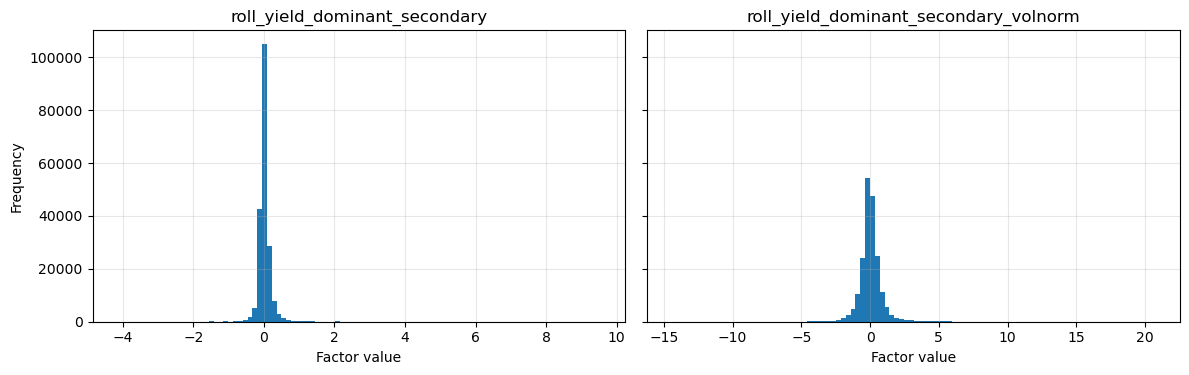

In [4]:
roll_raw = RollYieldFactor(
    combination='dominant_secondary', near_dte_min=0, far_dte_max=365,
    price_col='Close', volnorm=False,
)
roll_norm = RollYieldFactor(
    combination='dominant_secondary', near_dte_min=0, far_dte_max=365,
    price_col='Close', volnorm=True, vol_lookback=60, vol_min_periods=10,
)

roll_raw_values = roll_raw.compute(factor_data)
roll_norm_values = roll_norm.compute(factor_data)
representative_coverage = pd.DataFrame(
    {
        '有效值数量': [roll_raw_values.notna().sum(), roll_norm_values.notna().sum()],
        '覆盖率': [roll_raw_values.notna().mean(), roll_norm_values.notna().mean()],
        '结构化警告数量': [len(roll_raw.warnings), len(roll_norm.warnings)],
    },
    index=['raw', 'volnorm_60'],
)
display(representative_coverage.style.format({'覆盖率': '{:.2%}'}))
_ = xray.plot_hist(roll_raw_values, roll_norm_values, bins=100)

## 参数空间与因子预计算

- `near_next`：曲线前端的局部斜率。
- `near_dominant`：近月相对流动性锚点。
- `near_farthest`：较宽期限跨度的整体曲线斜率。
- `dominant_secondary`：最接近实际可交易换月组合。
- DTE `[0/14, 180/365]`：比较是否避开临近交割扰动，以及半年与一年曲线跨度。
- 波动率窗口 `20/60`：比较约一个月与一个季度的风险尺度。

In [5]:
structural_grid = {
    'combination': [
        'near_next', 'near_dominant', 'near_farthest', 'dominant_secondary',
    ],
    'near_dte_min': [0, 14],
    'far_dte_max': [180, 365],
    'price_col': ['Close'],
}
grid_norm = {
    **structural_grid,
    'volnorm': [True],
    'vol_lookback': [20, 60],
    'vol_min_periods': [10],
}
grid_raw = {**structural_grid, 'volnorm': [False]}

def precompute_with_diagnostics(
    param_grid: Mapping[str, Sequence[Hashable]],
) -> tuple[dict[tuple[Hashable, ...], pd.Series], pd.DataFrame]:
    """预计算因子值，同时保留覆盖率与结构化警告数量。"""
    values_map: dict[tuple[Hashable, ...], pd.Series] = {}
    diagnostics: list[dict[str, Any]] = []
    candidates = gen_candidate_grid(param_grid)
    for candidate in tqdm(candidates, desc='预计算因子', leave=False):
        params = dict(candidate.params)
        factor = RollYieldFactor(**params)
        values = factor.compute(factor_data)
        key = tuple(params.values())
        values_map[key] = values
        diagnostics.append({
            **params,
            'valid_count': int(values.notna().sum()),
            'coverage': float(values.notna().mean()),
            'warning_count': len(factor.warnings),
        })
    return values_map, pd.DataFrame(diagnostics)

factor_logger = logging.getLogger('factors.library.basic')
previous_level = factor_logger.level
factor_logger.setLevel(logging.ERROR)
try:
    data_norm, coverage_norm = precompute_with_diagnostics(grid_norm)
    data_raw, coverage_raw = precompute_with_diagnostics(grid_raw)
finally:
    factor_logger.setLevel(previous_level)

factor_values = data_norm | data_raw
coverage_table = pd.concat([coverage_norm, coverage_raw], ignore_index=True)
assert len(factor_values) == 48
display(coverage_table.sort_values(
    ['combination', 'volnorm', 'near_dte_min', 'far_dte_max', 'vol_lookback'],
    na_position='first',
).style.format({'coverage': '{:.2%}'}))

预计算因子:   0%|          | 0/32 [00:00<?, ?it/s]

预计算因子:   0%|          | 0/16 [00:00<?, ?it/s]

,combination,near_dte_min,far_dte_max,price_col,volnorm,vol_lookback,vol_min_periods,valid_count,coverage,warning_count
44,dominant_secondary,0,180,Close,False,nan,nan,144632,66.27%,61598
45,dominant_secondary,0,365,Close,False,nan,nan,198711,91.05%,8982
46,dominant_secondary,14,180,Close,False,nan,nan,141209,64.70%,65296
47,dominant_secondary,14,365,Close,False,nan,nan,195152,89.42%,12821
24,dominant_secondary,0,180,Close,True,20.000000,10.000000,144001,65.98%,61598
25,dominant_secondary,0,180,Close,True,60.000000,10.000000,144239,66.09%,61598
26,dominant_secondary,0,365,Close,True,20.000000,10.000000,197300,90.40%,8982
27,dominant_secondary,0,365,Close,True,60.000000,10.000000,197734,90.60%,8982
28,dominant_secondary,14,180,Close,True,20.000000,10.000000,140592,64.42%,65296
29,dominant_secondary,14,180,Close,True,60.000000,10.000000,140824,64.53%,65296


## 诊断组合参数扫描

对每组因子值扫描 `h=5, 10, ..., 60`，使用截面市场中性的 `market_rank_ls` 配方，以代理成本后收益的 Sharpe 与 CAGR 评价。

In [6]:
experiment_params = {'h': range(5, 65, 5)}
param_grid_norm = {**grid_norm, **experiment_params}
param_grid_raw = {**grid_raw, **experiment_params}
candidates = join_candidates_sequences(
    gen_candidate_grid(param_grid_norm),
    gen_candidate_grid(param_grid_raw),
)
assert len(candidates) == 576

norm_param_names = tuple(grid_norm)
raw_param_names = tuple(grid_raw)

def evaluate_mrls(params: Mapping[str, Any]) -> EvaluationResult:
    """运行一组截面市场中性诊断组合。"""
    factor_param_names = norm_param_names if params['volnorm'] else raw_param_names
    key = tuple(params[name] for name in factor_param_names)
    signal = replace(presets.base_signal, values=factor_values[key])
    rebalance = replace(presets.base_rebalance_config, interval=params['h'])
    spec = replace(presets.mrls_base_spec, rebalance=rebalance)
    runner = DiagnosticPortfolioExperimentRunner(
        signal=signal, dataset=dataset, spec=spec,
    )
    portfolio_result = runner.run()
    metrics = {
        'sharpe': float(portfolio_result.performance.loc['proxy_net', 'sharpe']),
        'cagr': float(portfolio_result.performance.loc['proxy_net', 'cagr']),
    }
    return EvaluationResult(
        metrics=metrics, warnings=tuple(portfolio_result.warnings),
    )

scan_result = run_scan(
    evaluate_func=evaluate_mrls,
    candidates=candidates,
    error_policy='raise',
    progress_bar=True,
    desc='扫描 RollYield 参数',
)


扫描 RollYield 参数:   0%|          | 0/576 [00:00<?, ?it/s]


扫描 RollYield 参数:   0%|          | 2/576 [00:00<03:01,  3.16it/s]


扫描 RollYield 参数:   1%|          | 3/576 [00:01<04:03,  2.35it/s]


扫描 RollYield 参数:   1%|          | 4/576 [00:01<04:34,  2.09it/s]


扫描 RollYield 参数:   1%|          | 5/576 [00:02<04:50,  1.97it/s]


扫描 RollYield 参数:   1%|          | 6/576 [00:02<04:58,  1.91it/s]

... (567 outputs left out)


扫描 RollYield 参数: 100%|█████████▉| 574/576 [05:59<00:01,  1.57it/s]


扫描 RollYield 参数: 100%|█████████▉| 575/576 [05:59<00:00,  1.60it/s]


扫描 RollYield 参数: 100%|██████████| 576/576 [06:00<00:00,  1.62it/s]


扫描 RollYield 参数: 100%|██████████| 576/576 [06:00<00:00,  1.60it/s]

## 完整结果与最优候选

In [7]:
scan_table = pd.concat(
    [scan_result.candidate_params, scan_result.eval_metrics], axis=1,
).sort_index()
scan_table.index.name = 'candidate_id'
assert len(scan_table) == 576

ranking = scan_table.sort_values(['sharpe', 'cagr'], ascending=False)
best_candidate = ranking.iloc[0]
print('最佳候选：')
display(best_candidate.to_frame('value'))
print('Sharpe 排名前 10：')
display(ranking.head(10))
print(f'完整候选结果（{len(scan_table)} 行）：')
with pd.option_context('display.max_rows', None):
    display(scan_table)

最佳候选：


,value
combination,near_dominant
near_dte_min,0
far_dte_max,365
price_col,Close
volnorm,False
vol_lookback,NaN
vol_min_periods,NaN
h,55
sharpe,1.571799
cagr,0.089873


Sharpe 排名前 10：


,combination,near_dte_min,far_dte_max,price_col,volnorm,vol_lookback,vol_min_periods,h,sharpe,cagr
candidate_id,,,,,,,,,,
cand_0454,near_dominant,0,365,Close,False,NaN,NaN,55,1.571799,0.089873
cand_0442,near_dominant,0,180,Close,False,NaN,NaN,55,1.469850,0.089452
cand_0455,near_dominant,0,365,Close,False,NaN,NaN,60,1.442589,0.081404
cand_0478,near_dominant,14,365,Close,False,NaN,NaN,55,1.435713,0.085713
cand_0452,near_dominant,0,365,Close,False,NaN,NaN,45,1.423304,0.080902
cand_0418,near_next,14,180,Close,False,NaN,NaN,55,1.422623,0.076033
cand_0390,near_next,0,180,Close,False,NaN,NaN,35,1.415710,0.076928
cand_0430,near_next,14,365,Close,False,NaN,NaN,55,1.411738,0.075262
cand_0490,near_farthest,0,180,Close,False,NaN,NaN,55,1.408210,0.080007


完整候选结果（576 行）：


,combination,near_dte_min,far_dte_max,price_col,volnorm,vol_lookback,vol_min_periods,h,sharpe,cagr
candidate_id,,,,,,,,,,
cand_0000,near_next,0,180,Close,True,20.0,10.0,5,0.821656,0.043162
cand_0001,near_next,0,180,Close,True,20.0,10.0,10,0.852799,0.045544
cand_0002,near_next,0,180,Close,True,20.0,10.0,15,0.818387,0.042875
cand_0003,near_next,0,180,Close,True,20.0,10.0,20,0.814513,0.043015
cand_0004,near_next,0,180,Close,True,20.0,10.0,25,0.759966,0.039146
cand_0005,near_next,0,180,Close,True,20.0,10.0,30,1.139403,0.059827
cand_0006,near_next,0,180,Close,True,20.0,10.0,35,1.258195,0.066450
cand_0007,near_next,0,180,Close,True,20.0,10.0,40,0.884467,0.045657
cand_0008,near_next,0,180,Close,True,20.0,10.0,45,1.161013,0.059853


## Sharpe 热力图

每行对应一种合约配对，左右分别为波动率归一与原始信号。横轴是四种 DTE 区间，纵轴是持有期；归一化信号对 20/60 日窗口取中位数。所有子图共享色标。

C:\Users\Jesse\AppData\Local\Temp\ipykernel_16432\1955027742.py:52: UserWarning: Glyph 21306 (\N{CJK UNIFIED IDEOGRAPH-533A}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Jesse\AppData\Local\Temp\ipykernel_16432\1955027742.py:52: UserWarning: Glyph 38388 (\N{CJK UNIFIED IDEOGRAPH-95F4}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Jesse\AppData\Local\Temp\ipykernel_16432\1955027742.py:52: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Jesse\AppData\Local\Temp\ipykernel_16432\1955027742.py:52: UserWarning: Glyph 33258 (\N{CJK UNIFIED IDEOGRAPH-81EA}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Jesse\AppData\Local\Temp\ipykernel_16432\1955027742.py:52: UserWarning: Glyph 28982 (\N{CJK UNIFIED IDEOGRAPH-7136}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Jesse\AppData\Local\Temp\ipykernel_16432\1955027742.py:52: UserWarning: Glyph 26085 (\

C:\Users\Jesse\AppData\Local\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 21306 (\N{CJK UNIFIED IDEOGRAPH-533A}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Jesse\AppData\Local\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 38388 (\N{CJK UNIFIED IDEOGRAPH-95F4}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Jesse\AppData\Local\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Jesse\AppData\Local\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 33258 (\N{CJK UNIFIED IDEOGRAPH-81EA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Jesse\AppData\Local\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 

C:\Users\Jesse\AppData\Local\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 21442 (\N{CJK UNIFIED IDEOGRAPH-53C2}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Jesse\AppData\Local\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Jesse\AppData\Local\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 25195 (\N{CJK UNIFIED IDEOGRAPH-626B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Jesse\AppData\Local\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 25551 (\N{CJK UNIFIED IDEOGRAPH-63CF}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Jesse\AppData\Local\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 

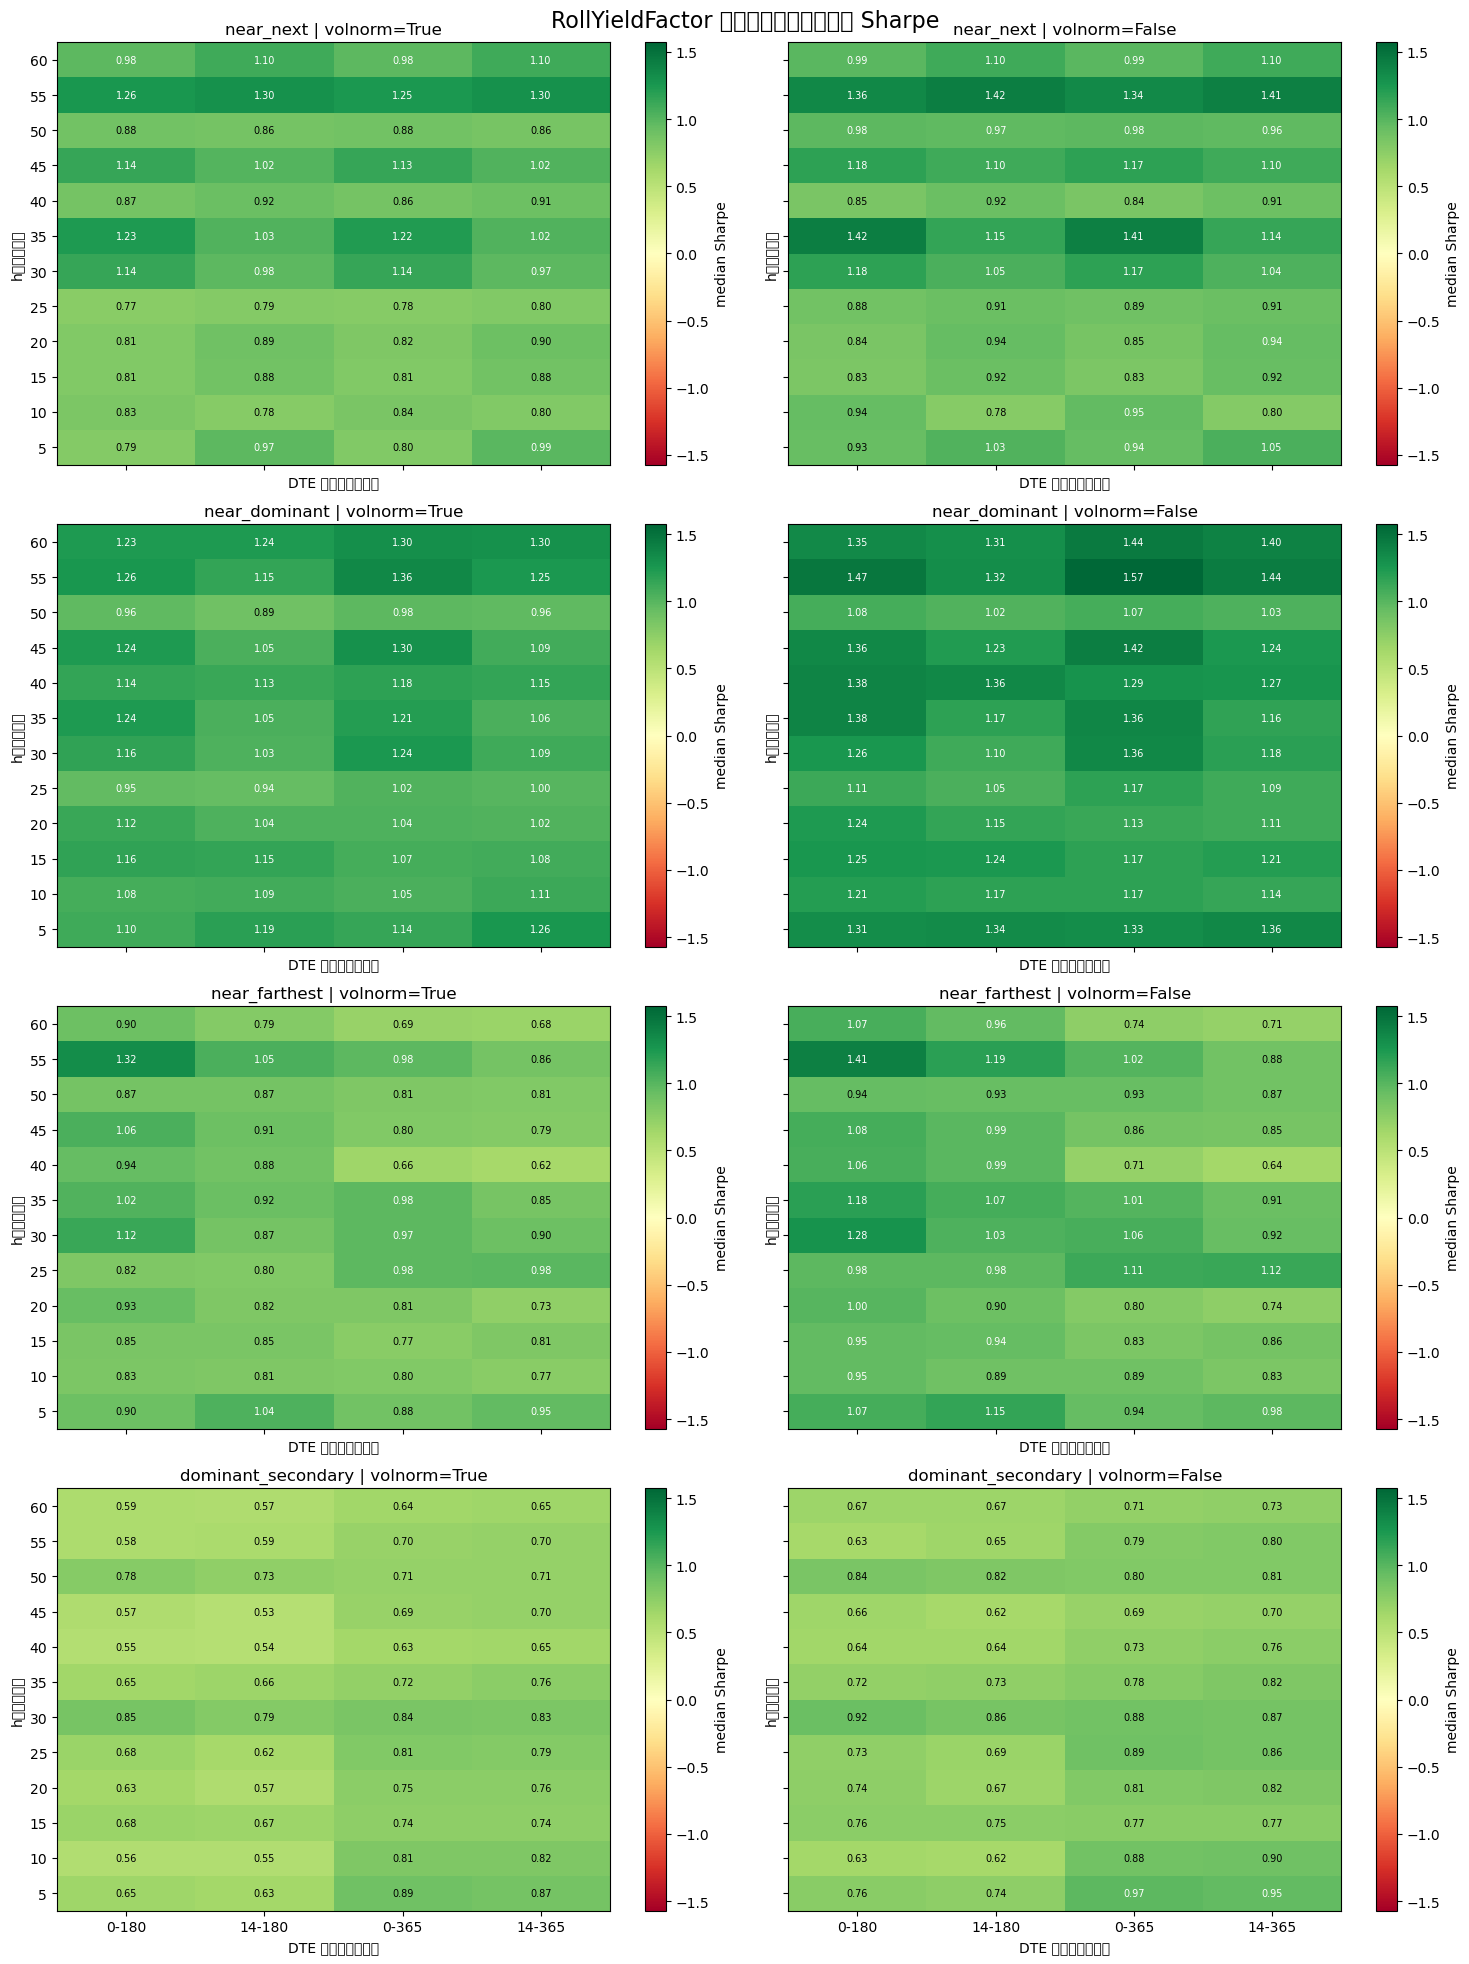

In [8]:
plot_data = scan_table.reset_index(drop=False).copy()
plot_data['dte_band'] = (
    plot_data['near_dte_min'].astype(str)
    + '-'
    + plot_data['far_dte_max'].astype(str)
)
dte_order = ['0-180', '14-180', '0-365', '14-365']
combinations = structural_grid['combination']
heat_stats = (
    plot_data.groupby(
        ['combination', 'volnorm', 'h', 'dte_band'], observed=True,
    )['sharpe']
    .median()
    .reset_index()
)
vabs = float(np.nanmax(np.abs(heat_stats['sharpe'].to_numpy())))
fig, axes = plt.subplots(
    len(combinations), 2, figsize=(15, 20), sharex=True, sharey=True,
)

for row, combination in enumerate(combinations):
    for col, volnorm in enumerate([True, False]):
        ax = axes[row, col]
        subset = heat_stats[
            (heat_stats['combination'] == combination)
            & (heat_stats['volnorm'] == volnorm)
        ]
        heat = (
            subset.pivot(index='h', columns='dte_band', values='sharpe')
            .reindex(index=list(range(5, 65, 5)), columns=dte_order)
        )
        image = ax.imshow(
            heat.to_numpy(), aspect='auto', origin='lower', cmap='RdYlGn',
            vmin=-vabs, vmax=vabs,
        )
        ax.set_xticks(range(len(dte_order)), dte_order)
        ax.set_yticks(range(len(heat.index)), heat.index)
        ax.set_xlabel('DTE 区间（自然日）')
        ax.set_ylabel('h（持有期）')
        ax.set_title(f'{combination} | volnorm={volnorm}')
        for i in range(heat.shape[0]):
            for j in range(heat.shape[1]):
                value = heat.iat[i, j]
                if pd.isna(value):
                    continue
                color = 'black' if abs(value) < 0.6 * vabs else 'white'
                ax.text(j, i, f'{value:.2f}', ha='center', va='center',
                        fontsize=7, color=color)
        fig.colorbar(image, ax=ax, label='median Sharpe')

fig.suptitle('RollYieldFactor 参数扫描：代理成本后 Sharpe', fontsize=16)
fig.tight_layout()
plt.show()

## 解释边界

以上结果是同一样本内的机制比较。最优候选使用了完整样本进行选择，不能直接视为样本外结论；后续应通过时间切分或 walk-forward 实验验证稳定性。